<a href="https://colab.research.google.com/github/iasd00022-lgtm/data-mining-adult-income/blob/iasd11-random-Forest/IASD11random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le dataset
df = pd.read_csv("/adult.csv")

# Afficher les 5 premières lignes
df.head()


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Remplacer les "?" par des vraies valeurs manquantes (NaN)
# Attention : pas d'espace avant le ?, on cherche exactement ce qu'il y a dans le fichier
df = df.replace('?', np.nan)
# Remplacer par la valeur la plus fréquente (le mode) pour chaque colonne
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Vérifier s'il reste des valeurs manquantes
print("Valeurs manquantes restantes :", df.isnull().sum().sum())




Valeurs manquantes restantes : 0


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

df.head() # Tout doit être en chiffres maintenant

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,3,77053,11,9,6,9,1,4,0,0,4356,40,38,0
1,82,3,132870,11,9,6,3,1,4,0,0,4356,18,38,0
2,66,3,186061,15,10,6,9,4,2,0,0,4356,40,38,0
3,54,3,140359,5,4,0,6,4,4,0,0,3900,40,38,0
4,41,3,264663,15,10,5,9,3,4,0,0,3900,40,38,0


In [ ]:
from sklearn.preprocessing import StandardScaler

X = df.drop('income', axis=1)
y = df['income']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

X.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,3.769612,-0.085296,-1.067997,0.181332,-0.420060,2.249480,0.720237,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-0.035429,0.26137
1,3.183112,-0.085296,-0.539169,0.181332,-0.420060,2.249480,-0.790092,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-1.817204,0.26137
2,2.010110,-0.085296,-0.035220,1.214869,-0.031360,2.249480,0.720237,1.589322,-1.962621,-1.422331,-0.14592,10.593507,-0.035429,0.26137
3,1.130359,-0.085296,-0.468215,-1.368974,-2.363558,-1.734058,-0.034928,1.589322,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.26137
4,0.177296,-0.085296,0.709482,1.214869,-0.031360,1.585557,0.720237,0.966947,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.26137


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (26048, 14)
Taille de X_test  : (6513, 14)


In [ ]:
print(X.dtypes.unique())
print(y.unique())

[dtype('float64')]
[0 1]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
import time

t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Entraînement terminé en {time.time() - t0:.1f} s")

y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

Entraînement terminé en 4.8 s


In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, matthews_corrcoef)

print("Accuracy          :", round(accuracy_score(y_test, y_pred), 3))
print("Précision         :", round(precision_score(y_test, y_pred), 3))
print("Rappel            :", round(recall_score(y_test, y_pred), 3))
print("F1-score          :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC           :", round(roc_auc_score(y_test, y_proba), 3))
print("Average Precision :", round(average_precision_score(y_test, y_proba), 3))
print("MCC               :", round(matthews_corrcoef(y_test, y_pred), 3))
print()
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

Accuracy          : 0.856
Précision         : 0.732
Rappel            : 0.617
F1-score          : 0.67
ROC-AUC           : 0.905
Average Precision : 0.778
MCC               : 0.582

              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4976
        >50K       0.73      0.62      0.67      1537

    accuracy                           0.86      6513
   macro avg       0.81      0.77      0.79      6513
weighted avg       0.85      0.86      0.85      6513



Observation :

L’accuracy est d’environ 0,86, mais elle est trompeuse : environ 76 % des individus gagnent moins de 50K, donc un modèle qui répondrait toujours « <=50K » aurait déjà 76 %. Il faut regarder le rappel et le F1. Le rappel est d’environ 0,61 : le modèle retrouve un peu plus de 6 hauts revenus sur 10. La précision est d’environ 0,73 : quand il annonce « >50K », il a raison environ 7 fois sur 10. Le ROC-AUC proche de 0,90 montre une bonne capacité de séparation des deux classes

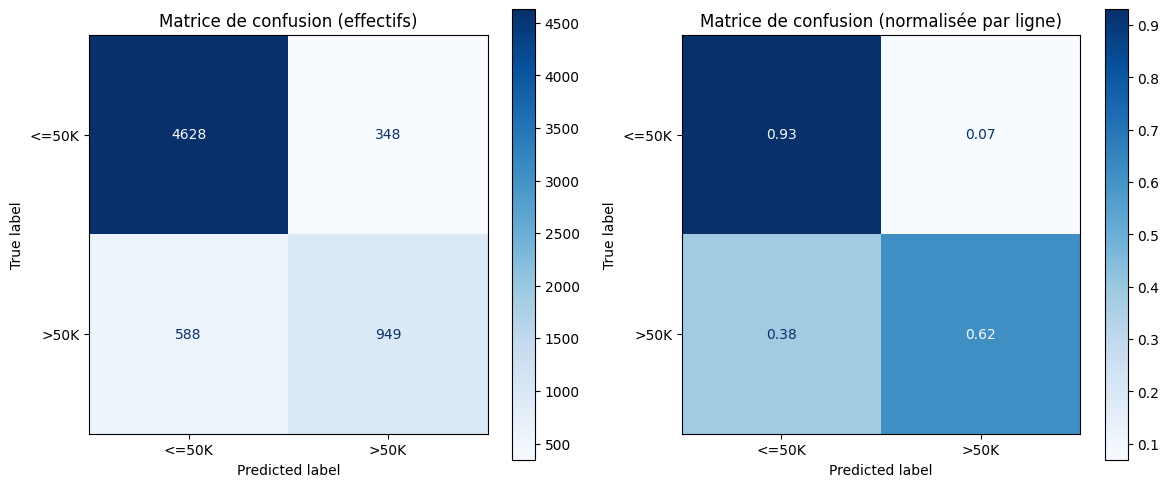

In [ ]:
import matplotlib.pyplot as plt
import os
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("results/figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["<=50K", ">50K"], cmap="Blues", ax=axes[0])
axes[0].set_title("Matrice de confusion (effectifs)")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["<=50K", ">50K"], cmap="Blues",
    normalize="true", values_format=".2f", ax=axes[1])
axes[1].set_title("Matrice de confusion (normalisée par ligne)")

plt.tight_layout()
plt.savefig("results/figures/rf_matrice_confusion.png", dpi=150)
plt.show()

Observation :

La diagonale contient les bonnes prédictions. Le modèle reconnaît très bien la classe « <=50K » (environ 93 à 94 % bien classés) mais moins bien la classe « >50K » (environ 60 %). Son erreur principale est donc de classer certains hauts revenus comme bas revenus (faux négatifs). C’est une conséquence du déséquilibre des classes.

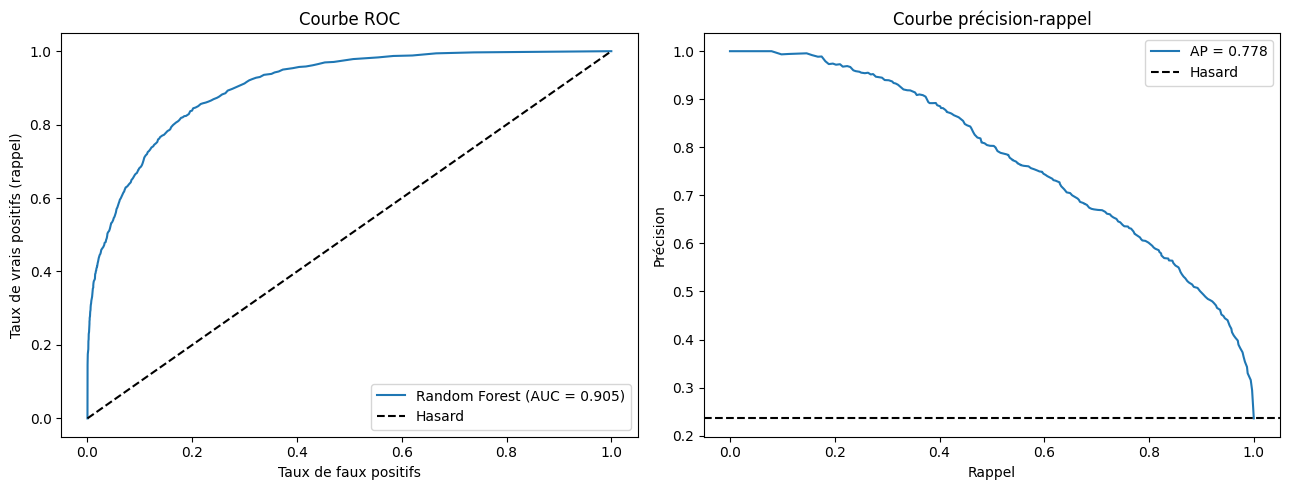

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Hasard")
axes[0].set_xlabel("Taux de faux positifs")
axes[0].set_ylabel("Taux de vrais positifs (rappel)")
axes[0].set_title("Courbe ROC")
axes[0].legend()

axes[1].plot(rec, prec, label=f"AP = {average_precision_score(y_test, y_proba):.3f}")
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="Hasard")
axes[1].set_xlabel("Rappel")
axes[1].set_ylabel("Précision")
axes[1].set_title("Courbe précision-rappel")
axes[1].legend()

plt.tight_layout()
plt.savefig("results/figures/rf_roc_precision_rappel.png", dpi=150)
plt.show()

Observation :

La courbe ROC est nettement au-dessus de la diagonale, ce qui confirme un bon pouvoir de discrimination. La courbe précision-rappel montre un compromis : quand on augmente le rappel (retrouver plus de hauts revenus), la précision diminue. Le seuil de décision par défaut (0,5) peut donc être ajusté selon l’objectif : privilégier la précision ou le rappel.

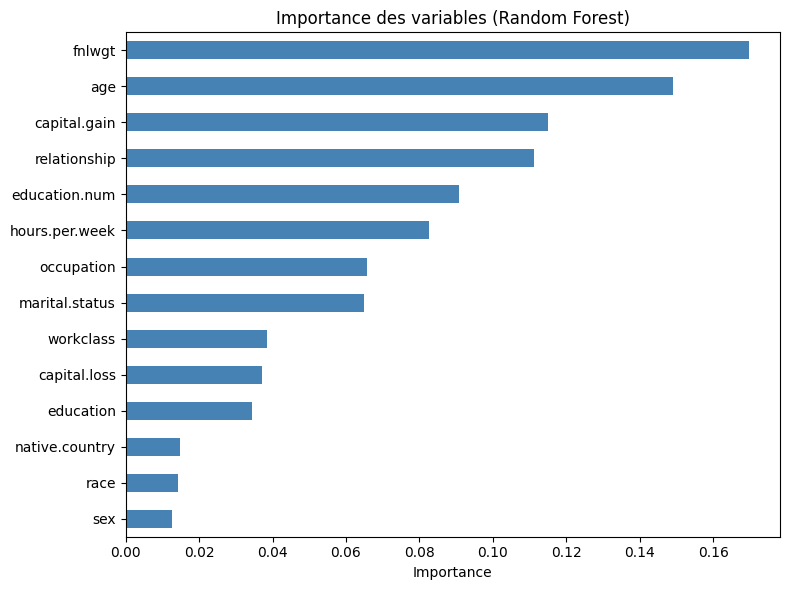

In [ ]:
import pandas as pd

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
imp.plot(kind="barh", color="steelblue")
plt.title("Importance des variables (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("results/figures/rf_importance_variables.png", dpi=150)
plt.show()

In [ ]:
from sklearn.model_selection import cross_validate, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(
    RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    X, df["income"] if "income" in df.columns else y, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    v = res[f"test_{m}"]
    print(f"{m:10s} : {v.mean():.3f} ± {v.std():.3f}")

accuracy   : 0.857 ± 0.003
precision  : 0.742 ± 0.007
recall     : 0.625 ± 0.012
f1         : 0.678 ± 0.008
roc_auc    : 0.907 ± 0.003


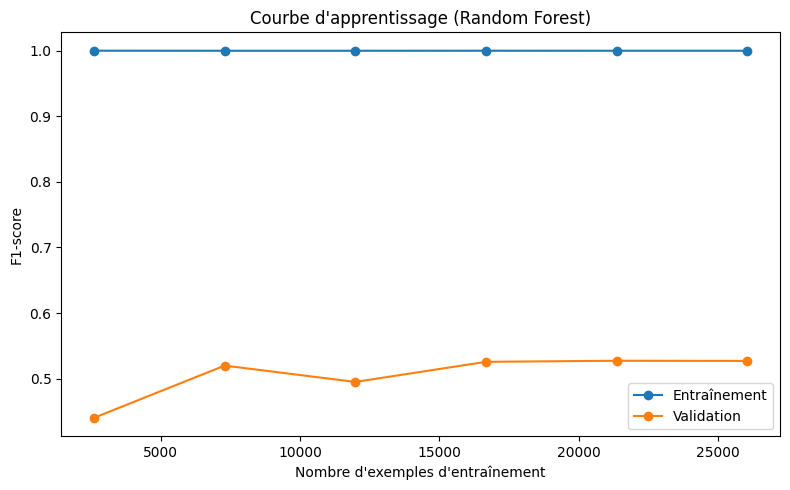

In [ ]:
from sklearn.model_selection import learning_curve
import numpy as np

sizes, train_sc, val_sc = learning_curve(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    X, y, cv=5, scoring="f1", train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)

plt.figure(figsize=(8, 5))
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="Entraînement")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="Validation")
plt.xlabel("Nombre d'exemples d'entraînement")
plt.ylabel("F1-score")
plt.title("Courbe d'apprentissage (Random Forest)")
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/rf_courbe_apprentissage.png", dpi=150)
plt.show()

bservation :

Le score d’entraînement est très proche de 1, alors que celui de validation est bien plus bas : l’écart montre un surapprentissage (le modèle mémorise les données d’entraînement). La courbe de validation continue à monter légèrement avec plus de données. Pour réduire l’écart, on peut limiter la profondeur des arbres (max_depth) ou augmenter min_samples_leaf.

Observation finale (cellule Texte)

Le Random Forest offre un bon compromis global (accuracy d’environ 0,86, ROC-AUC d’environ 0,90) et fait partie des meilleurs modèles du projet. Sa faiblesse est le rappel sur la classe « >50K » (environ 0,61), à cause du déséquilibre des classes. Pistes d’amélioration : class_weight="balanced", réglage des hyperparamètres, ou ajustement du seuil de décision.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    params, n_iter=15, scoring="f1", cv=3, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

print("Meilleurs paramètres :", search.best_params_)
best = search.best_estimator_
yb = best.predict(X_test)
print("F1 après réglage :", round(f1_score(y_test, yb), 3),
      "| Rappel :", round(recall_score(y_test, yb), 3),
      "| Précision :", round(precision_score(y_test, yb), 3))

Meilleurs paramètres : {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 30, 'class_weight': 'balanced'}
F1 après réglage : 0.703 | Rappel : 0.765 | Précision : 0.651
